In [1]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)


cuda


In [4]:

import os
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# Original dataset location
source_root = "/kaggle/input/datasets/zarintasnimadiba/rose-and-marigold-leaf-disease/Rose and Marigold Leaf Disease Image Dataset for M/Rose And MArigold Leaf Disease./Perfect Data Set"

# Seven classification folders
class_folders = {
    "Marigold_Alternaria_Leaf_Blight": os.path.join(source_root, "marigold", "Alternaria Leaf Blight"),
    "Marigold_Healthy_Leaves": os.path.join(source_root, "marigold", "Helathy Leaves"),
    "Marigold_Pest_Damaged": os.path.join(source_root, "marigold", "Pest Damaged"),
    "Rose_Healthy": os.path.join(source_root, "rose", "Healthy"),
    "Rose_Pest_Damage": os.path.join(source_root, "rose", "Pest Damage"),
    "Rose_Rose_Mosaic_Virus": os.path.join(source_root, "rose", "Rose Mosaic Virus"),
    "Rose_Botrytis_Blight": os.path.join(source_root, "rose", "botrytis blight")
}

# Create an organized folder structure
organized_root = "/kaggle/working/rose_marigold_7class"
os.makedirs(organized_root, exist_ok=True)

for class_name, source_folder in class_folders.items():

    if not os.path.isdir(source_folder):
        raise FileNotFoundError(source_folder)

    link_path = os.path.join(organized_root, class_name)

    if not os.path.lexists(link_path):
        os.symlink(source_folder, link_path)

# Image preprocessing
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

# Load dataset using ImageFolder
all_data = datasets.ImageFolder(
    root=organized_root,
    transform=train_transform
)

class_names = all_data.classes

# Display class information
print("Classes:", class_names)
print("\nTotal images:", len(all_data))

print("\nImages in each class:")

class_counts = np.bincount(
    all_data.targets,
    minlength=len(class_names)
)

for name, count in zip(class_names, class_counts):
    print(name, ":", count)

# Split dataset: 70% training, 15% validation, 15% testing
indices = np.arange(len(all_data))
labels = np.array(all_data.targets)

train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=labels[temp_indices]
)

# Create separate datasets
train_data = Subset(all_data, train_indices)
val_data = Subset(all_data, val_indices)
test_data = Subset(all_data, test_indices)

print("\nDataset Splitting Results:")
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))


# Training transformation (same as Sir's code)
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor()
])

# Validation and testing transformation
val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

# Create datasets with separate transformations
train_dataset_full = datasets.ImageFolder(
    root=organized_root,
    transform=train_transform
)

eval_dataset_full = datasets.ImageFolder(
    root=organized_root,
    transform=val_transform
)

# Apply the previously created stratified split
train_data = Subset(train_dataset_full, train_indices)
val_data = Subset(eval_dataset_full, val_indices)
test_data = Subset(eval_dataset_full, test_indices)

print("Training, validation and testing datasets are ready.")
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))


Classes: ['Marigold_Alternaria_Leaf_Blight', 'Marigold_Healthy_Leaves', 'Marigold_Pest_Damaged', 'Rose_Botrytis_Blight', 'Rose_Healthy', 'Rose_Pest_Damage', 'Rose_Rose_Mosaic_Virus']

Total images: 3449

Images in each class:
Marigold_Alternaria_Leaf_Blight : 338
Marigold_Healthy_Leaves : 273
Marigold_Pest_Damaged : 78
Rose_Botrytis_Blight : 558
Rose_Healthy : 1167
Rose_Pest_Damage : 790
Rose_Rose_Mosaic_Virus : 245

Dataset Splitting Results:
Training images: 2414
Validation images: 517
Testing images: 518
Training, validation and testing datasets are ready.
Training: 2414
Validation: 517
Testing: 518


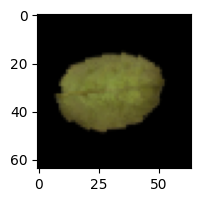

In [5]:

plt.figure(figsize=(2,2))
plt.imshow(train_data[800][0].permute(1,2,0))


In [13]:

#important HyperParameters
batch_size = 32
learning_rate = 0.001
minimum_learning_rate = 1e-4
epochs = 30


In [14]:

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 76
Validation batches: 17
Testing batches: 17


In [15]:

from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR

class CNNModel(nn.Module):
    def __init__(self, num_classes=2):
        super(CNNModel, self).__init__()

        # Convolutional layers
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3),
            nn.MaxPool2d(2),
            nn.ReLU()
        )

        # Fully connected layers
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*6*6, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

# 1. Get the Model
model = CNNModel(num_classes=len(class_names)).to(device)

# 2. Define optimizer
optimizer = Adam(model.parameters(), lr=learning_rate)

# 3. Define LR scheduler
scheduler = CosineAnnealingLR(
    optimizer,
    T_max=epochs,
    eta_min=minimum_learning_rate
)

# 4. Define loss function
criterion = nn.CrossEntropyLoss()

from torchsummary import summary
summary(model, input_size=(3,64,64));


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 62, 62]           1,792
         MaxPool2d-2           [-1, 64, 31, 31]               0
              ReLU-3           [-1, 64, 31, 31]               0
            Conv2d-4          [-1, 128, 29, 29]          73,856
         MaxPool2d-5          [-1, 128, 14, 14]               0
              ReLU-6          [-1, 128, 14, 14]               0
            Conv2d-7          [-1, 128, 12, 12]         147,584
         MaxPool2d-8            [-1, 128, 6, 6]               0
              ReLU-9            [-1, 128, 6, 6]               0
          Flatten-10                 [-1, 4608]               0
           Linear-11                  [-1, 256]       1,179,904
             ReLU-12                  [-1, 256]               0
          Dropout-13                  [-1, 256]               0
           Linear-14                   

In [23]:

def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        total_loss += loss.item()

        # compute accuracy
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(loader)
    train_acc = correct / total

    return train_loss, train_acc


def validate_epoch(model, loader, criterion, device):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    val_loss = total_loss / len(loader)
    val_acc = correct / total

    return val_loss, val_acc


In [24]:

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):
    print(f"----------------------------------------------------")
    print(f"Epoch {epoch+1}/{epochs}, LR: {optimizer.param_groups[0]['lr']:.6g}")

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
    scheduler.step()

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")


----------------------------------------------------
Epoch 1/30, LR: 0.001
Train Loss: 1.5483 | Train Acc: 0.3948
Val Loss: 1.2800 | Val Acc: 0.5300
----------------------------------------------------
Epoch 2/30, LR: 0.000997535
Train Loss: 1.2962 | Train Acc: 0.5104
Val Loss: 1.1647 | Val Acc: 0.5609
----------------------------------------------------
Epoch 3/30, LR: 0.000990166
Train Loss: 1.2027 | Train Acc: 0.5493
Val Loss: 1.1733 | Val Acc: 0.5880
----------------------------------------------------
Epoch 4/30, LR: 0.000977975
Train Loss: 1.1055 | Train Acc: 0.5998
Val Loss: 0.9633 | Val Acc: 0.6170
----------------------------------------------------
Epoch 5/30, LR: 0.000961095
Train Loss: 1.0517 | Train Acc: 0.6197
Val Loss: 0.9691 | Val Acc: 0.6190
----------------------------------------------------
Epoch 6/30, LR: 0.000939711
Train Loss: 0.9843 | Train Acc: 0.6338
Val Loss: 0.9755 | Val Acc: 0.6576
----------------------------------------------------
Epoch 7/30, LR: 0.00091

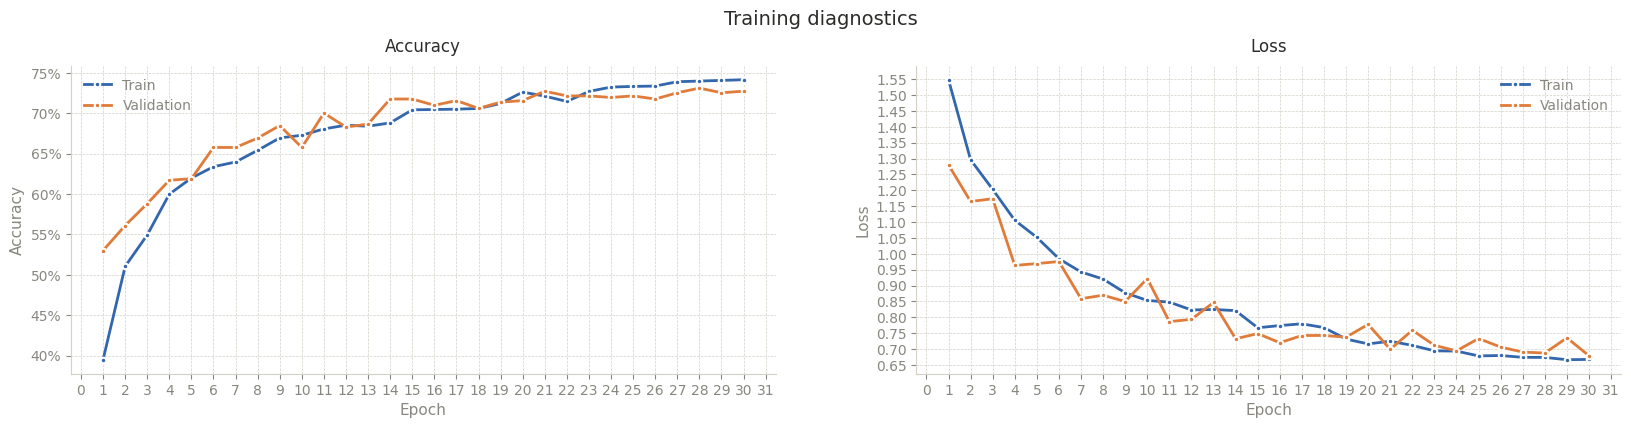

In [25]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import numpy as np

BLUE   = "#3266ad"
ORANGE = "#e07b39"
GRAY   = "#88877f"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#d3d1c7",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": "#d3d1c7",
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

epochs_number = np.arange(1, epochs + 1)
fig = plt.figure(figsize=(20, 4))
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.2)

# Accuracy
ax1 = fig.add_subplot(gs[0])
ax1.plot(epochs_number, train_accuracies, color=BLUE, lw=2,
         label="Train", marker="o", ms=4, mew=1.5, mec="white")
ax1.plot(epochs_number, val_accuracies, color=ORANGE, lw=2,
         label="Validation", marker="o", ms=4, mew=1.5,
         mec="white", linestyle="-")

ax1.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%")
)
ax1.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax1.set_ylabel("Accuracy", color=GRAY, fontsize=11)
ax1.set_title("Accuracy", fontsize=12,
              fontweight="medium", color="#2c2c2a", pad=10)
ax1.legend(frameon=False, fontsize=10, labelcolor=GRAY)

# Loss
ax2 = fig.add_subplot(gs[1])
ax2.plot(epochs_number, train_losses, color=BLUE, lw=2,
         label="Train", marker="o", ms=4, mew=1.5, mec="white")
ax2.plot(epochs_number, val_losses, color=ORANGE, lw=2,
         label="Validation", marker="o", ms=4, mew=1.5,
         mec="white", linestyle="-")

ax2.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax2.yaxis.set_major_locator(mticker.MultipleLocator(0.05))
ax2.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax2.set_ylabel("Loss", color=GRAY, fontsize=11)
ax2.set_title("Loss", fontsize=12,
              fontweight="medium", color="#2c2c2a", pad=10)
ax2.legend(frameon=False, fontsize=10, labelcolor=GRAY)

fig.suptitle("Training diagnostics", fontsize=14,
             fontweight="medium", color="#2c2c2a", y=1.02)

plt.savefig("training_curves.pdf", bbox_inches="tight", dpi=150)
plt.show()


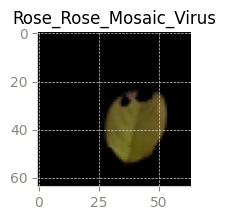

In [26]:

ix = torch.randint(0, len(train_data), ()).item()

img = train_data[ix][0].unsqueeze(0).to(device)

np_output = model(img).cpu().detach().numpy()

pred = np.exp(np_output) / np.sum(np.exp(np_output))

plt.figure(figsize=(2,2))

plt.imshow(img.squeeze(0).permute(1,2,0).cpu().detach().numpy())

plt.title(class_names[pred[0].argmax()])

plt.show()


Classes: ['Marigold_Alternaria_Leaf_Blight', 'Marigold_Healthy_Leaves', 'Marigold_Pest_Damaged', 'Rose_Botrytis_Blight', 'Rose_Healthy', 'Rose_Pest_Damage', 'Rose_Rose_Mosaic_Virus']
Total misclassified samples: 153


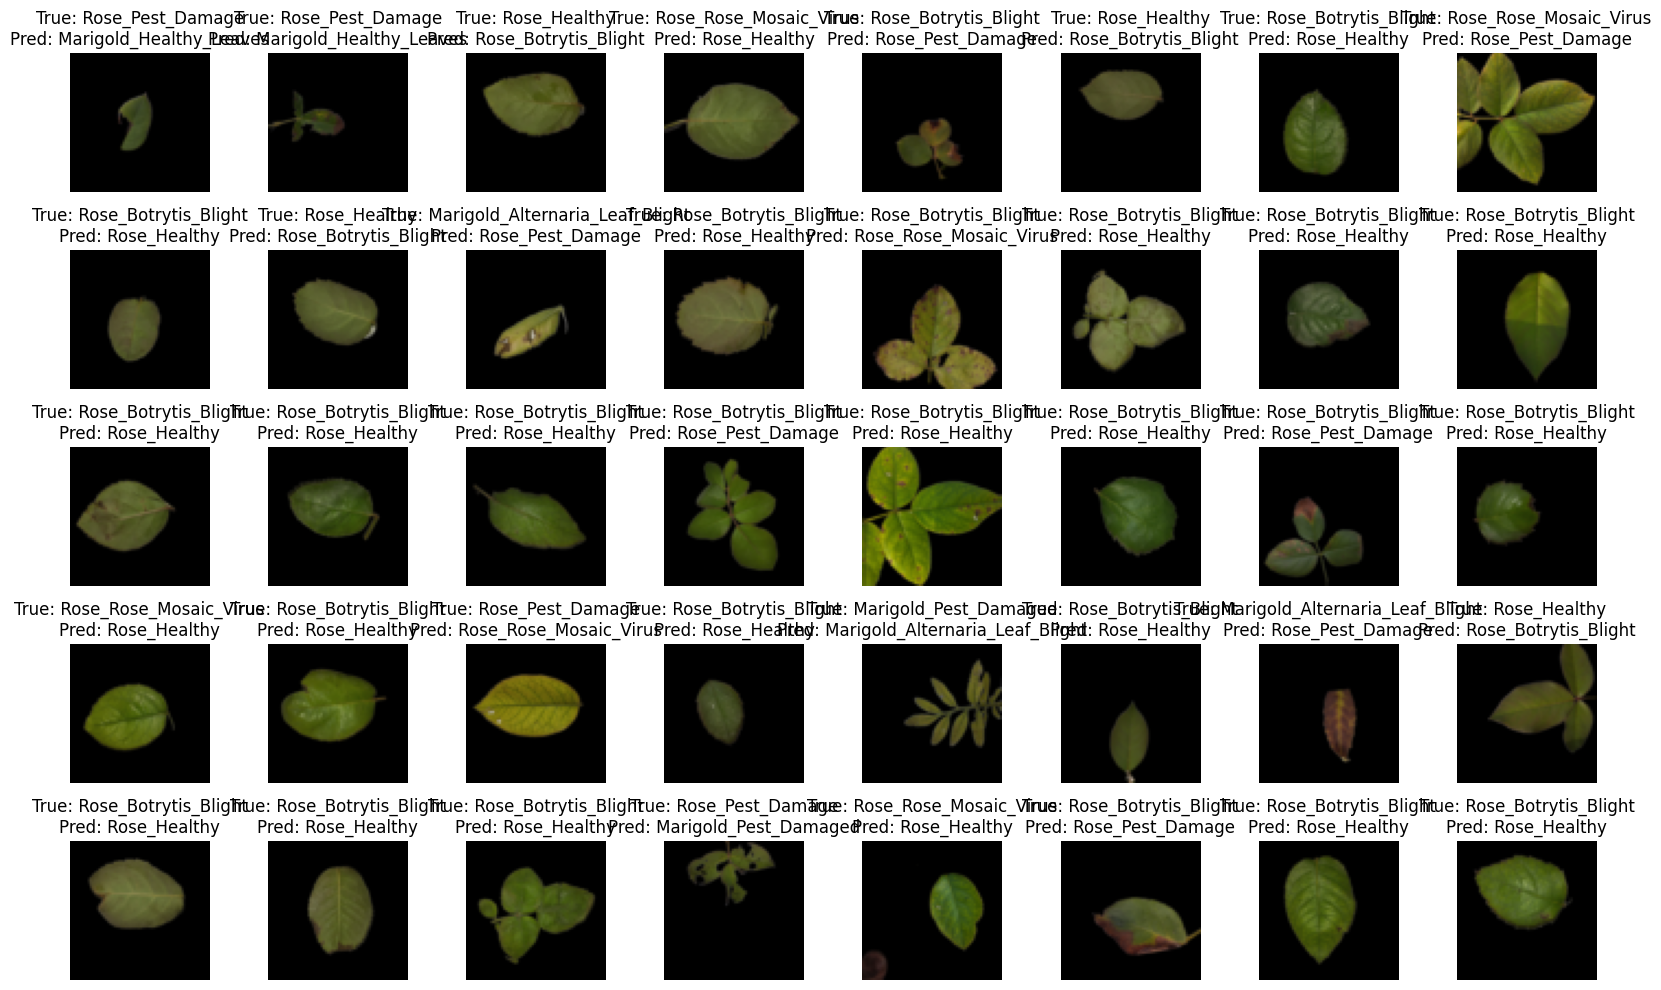

In [28]:

import torch
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Get class names from the original ImageFolder dataset
class_names = train_data.dataset.classes

print("Classes:", class_names)

model.eval()

misclassified = []
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        # Save all predictions and labels for confusion matrix
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        # Store misclassified images
        for img, true, pred in zip(images, labels, preds):
            if true != pred:
                misclassified.append(
                    (img.cpu(), true.item(), pred.item())
                )

print(f"Total misclassified samples: {len(misclassified)}")

# Display misclassified images
num_rows = 5
num_cols = 8

num_to_show = min(num_rows * num_cols, len(misclassified))

fig, axes = plt.subplots(
    num_rows, num_cols,
    figsize=(num_cols*2, num_rows*2)
)

axes = axes.flatten()

for idx in range(num_to_show):

    img, true, pred = misclassified[idx]

    img = img.permute(1, 2, 0)
    img = img * 255
    img = img.numpy().astype(np.uint8)

    axes[idx].imshow(img)

    axes[idx].set_title(
        f"True: {class_names[true]}\nPred: {class_names[pred]}"
    )

    axes[idx].axis('off')

# Turn off unused subplots
for idx in range(num_to_show, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()



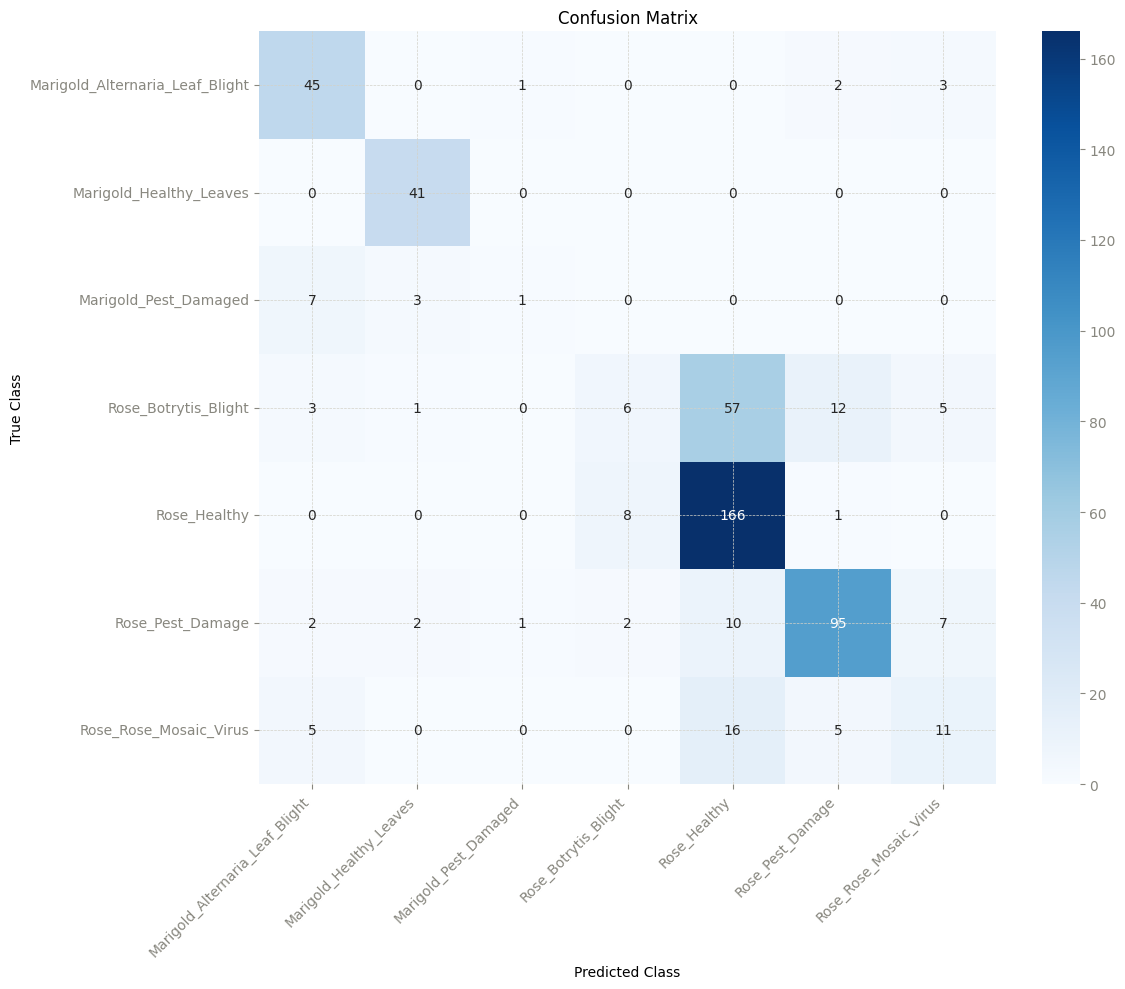

In [29]:

# Confusion Matrix

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()
